In [ ]:
print("bonjour,mon projet commence")


bonjour,mon projet commence


In [ ]:
!unzip "spotify-tracks-dataset.csv"
!ls

Archive:  spotify-tracks-dataset.csv
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of spotify-tracks-dataset.csv or
        spotify-tracks-dataset.csv.zip, and cannot find spotify-tracks-dataset.csv.ZIP, period.
__MACOSX  sample_data  spotify-tracks-dataset.csv


In [2]:
import pandas as pd
df = pd.read_csv("spotify-tracks-dataset.csv")
df.head()

,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [7]:
df = df.loc[:, ~df.columns.str.lower().str.startswith("unnamed")]
print(df.shape)
print(df.columns)

(114000, 20)
Index(['track_id', 'artists', 'album_name', 'track_name', 'popularity',
       'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness',
       'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness',
       'valence', 'tempo', 'time_signature', 'track_genre'],
      dtype='object')


In [8]:
df.isnull().sum()

,0
track_id,0
artists,1
album_name,1
track_name,1
popularity,0
duration_ms,0
explicit,0
danceability,0
energy,0
key,0


In [9]:
df.groupby("track_genre")["danceability"].mean().sort_values(ascending=False).head(10)

,danceability
track_genre,
kids,0.778906
chicago-house,0.766176
reggaeton,0.758521
latino,0.757057
reggae,0.745331
hip-hop,0.736154
dancehall,0.734169
minimal-techno,0.729395
detroit-techno,0.722568


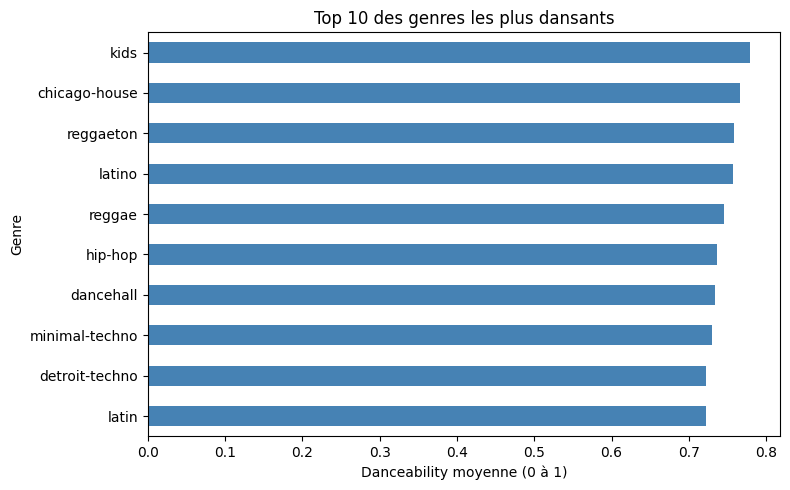

(0.7, 0.8)

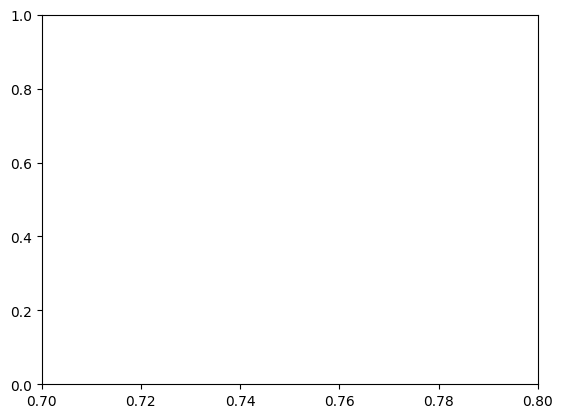

In [12]:
import matplotlib.pyplot as plt

top10 = df.groupby("track_genre")["danceability"].mean().sort_values(ascending=False).head(10)

top10.sort_values().plot(kind="barh", figsize=(8, 5), color="steelblue")
plt.title("Top 10 des genres les plus dansants")
plt.xlabel("Danceability moyenne (0 à 1)")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()
plt.xlim(0.7, 0.8)


In [13]:
cols = ["danceability", "energy", "valence", "tempo", "loudness", "acousticness", "speechiness", "duration_ms"]

df[cols + ["popularity"]].corr()["popularity"].drop("popularity").sort_values()

,popularity
speechiness,-0.044927
valence,-0.040534
acousticness,-0.025472
duration_ms,-0.007101
energy,0.001056
tempo,0.013205
danceability,0.035448
loudness,0.050423


In [14]:
df.groupby("track_genre")["popularity"].mean().sort_values(ascending=False).head(10)

,popularity
track_genre,
pop-film,59.283
k-pop,56.896
chill,53.651
sad,52.379
grunge,49.594
indian,49.539
anime,48.772
emo,48.128
sertanejo,47.866


In [ ]:
df["track_genre"].value_counts().describe()

In [ ]:
df["popularity"].mean()

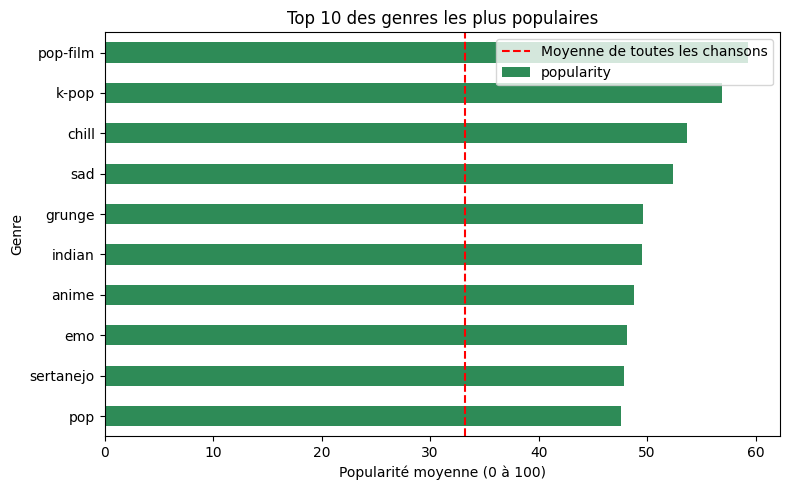

In [15]:
top10_pop = df.groupby("track_genre")["popularity"].mean().sort_values(ascending=False).head(10)

top10_pop.sort_values().plot(kind="barh", figsize=(8, 5), color="seagreen")
plt.axvline(df["popularity"].mean(), color="red", linestyle="--", label="Moyenne de toutes les chansons")
plt.title("Top 10 des genres les plus populaires")
plt.xlabel("Popularité moyenne (0 à 100)")
plt.ylabel("Genre")
plt.legend()
plt.tight_layout()
plt.show()

/tmp/ipykernel_529/3408169558.py:1: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc="lower right")


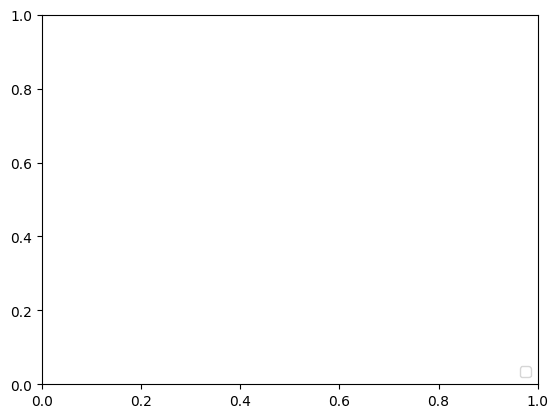

In [17]:
plt.legend(loc="lower right")

In [16]:
df["track_genre"].value_counts().describe()

,count
count,114.0
mean,1000.0
std,0.0
min,1000.0
25%,1000.0
50%,1000.0
75%,1000.0
max,1000.0


Conclusion : le genre musical explique mieux la popularité d’une chanson que ses caractéristiques sonores. Une chanson dansante n’est pas forcément populaire : les genres les plus dansants ne figurent pas parmi les plus populaires.

Limites : une corrélation n’est pas une cause. Le jeu de données contient 1 000 chansons par genre, donc il ne reflète pas ce que les gens écoutent réellement. La popularité dépend aussi de facteurs absents ici (artiste, promotion, playlists, date de sortie).